# 정류장 간 버스 통행시간 예측 실습 코드

- **Part 1. 데이터**: 패키지 설치 → 허깅페이스에서 데이터 받기 → 불러오기 → 둘러보기
- **Part 2. 모델**: 검증 나누기 → 평균 예측 → 피처 만들기 → LightGBM → 제출 파일과 채점

예측 대상은 `tt_sec`(출발 정류장 도착 → 다음 정류장 도착, 초)임.

---
# Part 1. 데이터

## 1-0. 패키지 설치
필요한 패키지를 정해진 버전으로 설치함. **처음 한 번만** 실행하면 됨.

- **Python 3.12 환경**에서 실행함. 3.11 이하이거나 3.15이면 설치가 실패함.
  아직 환경이 없으면 터미널(Anaconda Prompt)에서 `conda create -n bis python=3.12 -y`로 만들고, 커널을 `bis`로 고른 뒤 실행함.
- 설치가 끝나면 **커널을 재시작**한 뒤 다음 셀로 넘어감.

In [ ]:
import sys
assert (3, 12) <= sys.version_info[:2] <= (3, 14), f'지금 Python {sys.version.split()[0]}. 3.12 환경을 만들어 커널로 고를 것 (README 4. 시작하기)'
%pip install -r ../requirements.txt

## 1-1. 데이터 받기
허깅페이스에서 데이터를 내려받음.

- 처음에는 연습용 데이터(`'practice'`)로 끝까지 돌려 봄. **대회 때는 `PHASE = 'final'`로 바꾸면** 대회 데이터로 같은 노트북이 돌아감.

In [1]:
import os, sys
from pathlib import Path

PHASE = 'practice'          # 연습용: 'practice' / 대회: 'final'
REPO_ID = {'practice': 'CAMUS-LAB/bis-travel-time-practice',
           'final': 'CAMUS-LAB/bis-travel-time-final'}[PHASE]
DATA = Path('../data') / PHASE

if not (DATA / 'train.parquet').exists():
    from huggingface_hub import snapshot_download
    snapshot_download(repo_id=REPO_ID, repo_type='dataset', local_dir=DATA)
print('데이터 위치:', DATA)
print(sorted(p.name for p in DATA.iterdir() if p.is_file()))

데이터 위치: ../data/practice
['test.csv', 'test.parquet', 'train.csv', 'train.parquet']


## 1-2. 불러오기
CSV와 parquet은 내용이 같음. parquet이 작고 빨라서 parquet을 읽음.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

train = pd.read_parquet(DATA / 'train.parquet')
test = pd.read_parquet(DATA / 'test.parquet')
print('train', train.shape, '| test', test.shape)
print('test에 정답(tt_sec) 있음:', 'tt_sec' in test.columns)
train.head()

train (109891, 24) | test (79942, 24)
test에 정답(tt_sec) 있음: True


,row_id,route_id,route_nm,route_type,vehicle_id,direction,interval_wd,interval_sat,interval_sun,first_time,...,from_lon,to_stop,to_name,to_lat,to_lon,stop_seq,dist_m,date,arrive_hour,tt_sec
0,PTR0000000,DJB30300100,1,1,DJB130752344,0,8,9,10,525,...,127.31839,DJB8002678,진잠중학교,36.296320,127.31730,2,259,2024-09-23,7,60
1,PTR0000001,DJB30300100,1,1,DJB130752344,0,8,9,10,525,...,127.31730,DJB8002676,원내동,36.298800,127.31613,3,335,2024-09-23,7,73
2,PTR0000002,DJB30300100,1,1,DJB130752344,0,8,9,10,525,...,127.31613,DJB8002351,원내네거리,36.299770,127.31898,4,343,2024-09-23,7,73
3,PTR0000003,DJB30300100,1,1,DJB130752344,0,8,9,10,525,...,127.31898,DJB8001915,샘물타운아파트,36.299730,127.32204,5,276,2024-09-23,7,112
4,PTR0000004,DJB30300100,1,1,DJB130752344,0,8,9,10,525,...,127.32204,DJB8001153,구봉마을5단지,36.300285,127.32697,6,545,2024-09-23,7,134


## 1-3. 둘러보기
### 컬럼과 결측

In [3]:
info = pd.DataFrame({'dtype': train.dtypes.astype(str), '결측 수': train.isna().sum(), '고유값 수': train.nunique()})
info

,dtype,결측 수,고유값 수
row_id,str,0,109891
route_id,str,0,4
route_nm,str,0,4
route_type,int64,0,2
vehicle_id,str,0,89
direction,int64,0,2
interval_wd,int64,0,4
interval_sat,int64,0,3
interval_sun,int64,0,3
first_time,int64,0,3


### 날짜와 노선

In [4]:
print('train 날짜:', train.date.value_counts().sort_index().to_dict())
print('test  날짜:', test.date.value_counts().sort_index().to_dict())
print()
print(train.groupby('route_nm').agg(행수=('tt_sec', 'size'), 차량수=('vehicle_id', 'nunique'),
                                    정류장수=('from_stop', 'nunique'), 평균통행시간=('tt_sec', 'mean')).round(1))

train 날짜: {'2024-09-23': 28783, '2024-09-24': 28870, '2024-09-25': 28887, '2024-09-28': 23351}
test  날짜: {'2024-09-26': 28853, '2024-09-27': 28713, '2024-09-29': 22376}

             행수  차량수  정류장수  평균통행시간
route_nm                          
1         17377   21    42   160.0
102       47679   34    88   108.9
511       20620   14    65    98.5
605       24215   20    77   115.4


### 정답 `tt_sec` 분포

count    109891.0
mean        116.5
std         105.2
min           7.0
25%          56.0
50%          89.0
75%         150.0
max        1775.0


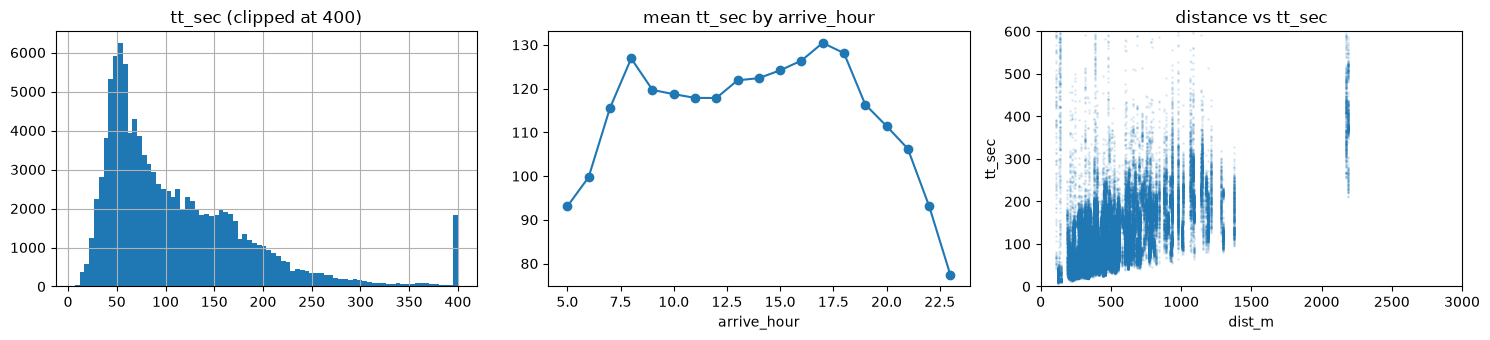

In [5]:
print(train.tt_sec.describe().round(1).to_string())

fig, ax = plt.subplots(1, 3, figsize=(15, 3.5))
train.tt_sec.clip(upper=400).hist(bins=80, ax=ax[0]); ax[0].set_title('tt_sec (clipped at 400)')
train.groupby('arrive_hour').tt_sec.mean().plot(ax=ax[1], marker='o'); ax[1].set_title('mean tt_sec by arrive_hour')
ax[2].scatter(train.dist_m, train.tt_sec, s=1, alpha=0.1); ax[2].set_xlim(0, 3000); ax[2].set_ylim(0, 600)
ax[2].set_xlabel('dist_m'); ax[2].set_ylabel('tt_sec'); ax[2].set_title('distance vs tt_sec')
plt.tight_layout(); plt.show()

### 노선 모양
정류장 좌표를 찍어 보면 노선이 어디를 지나는지 보임.

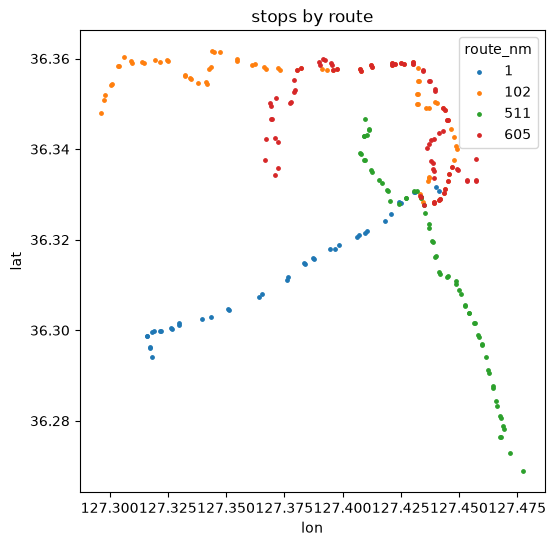

In [6]:
stops = train.drop_duplicates(['route_nm', 'from_stop'])
fig, ax = plt.subplots(figsize=(6, 6))
for nm, g in stops.groupby('route_nm'):
    ax.scatter(g.from_lon, g.from_lat, s=6, label=nm)
ax.legend(title='route_nm'); ax.set_xlabel('lon'); ax.set_ylabel('lat'); ax.set_title('stops by route')
plt.show()

### 차량 한 대의 운행 기록
데이터는 날짜 → 노선 → 차량 → 시간 → 방향 → 정류장 순번 순으로 정렬되어 있음.

In [7]:
one = train[(train.vehicle_id == train.vehicle_id.iloc[0]) & (train.date == train.date.iloc[0])]
one[['date', 'route_nm', 'vehicle_id', 'arrive_hour', 'direction', 'stop_seq', 'from_name', 'to_name', 'dist_m', 'tt_sec']].head(15)

,date,route_nm,vehicle_id,arrive_hour,direction,stop_seq,from_name,to_name,dist_m,tt_sec
0,2024-09-23,1,DJB130752344,7,0,2,서대전IC,진잠중학교,259,60
1,2024-09-23,1,DJB130752344,7,0,3,진잠중학교,원내동,335,73
2,2024-09-23,1,DJB130752344,7,0,4,원내동,원내네거리,343,73
3,2024-09-23,1,DJB130752344,7,0,5,원내네거리,샘물타운아파트,276,112
4,2024-09-23,1,DJB130752344,7,0,6,샘물타운아파트,구봉마을5단지,545,134
5,2024-09-23,1,DJB130752344,7,0,7,구봉마을5단지,신선마을아파트,257,51
6,2024-09-23,1,DJB130752344,7,0,8,신선마을아파트,건양대병원네거리,1295,122
7,2024-09-23,1,DJB130752344,7,0,9,건양대병원네거리,가수원육교.가수원시장,737,117
8,2024-09-23,1,DJB130752344,7,0,10,가수원육교.가수원시장,정림삼거리,1176,227
9,2024-09-23,1,DJB130752344,7,0,11,정림삼거리,도마삼거리,1190,184


---
# Part 2. 모델

## 2-1. 검증 방법
학습 데이터 중 **수요일(9/25)을 검증용**으로 떼어 놓고, 나머지(월·화·토)로 학습함.

- 학습 날짜는 월·화·수·토, 평가 날짜는 목·금·일임. 검증도 이렇게 **날짜 단위**로 나눠야 평가 상황과 비슷해짐.
- 단, 수요일 하나만 검증하면 **주말(일요일) 예측이 얼마나 맞는지는 확인되지 않음**. 학습 데이터의 주말은 토요일 하루뿐임.
  날짜를 하나씩 돌아가며 검증하면(월→화→수→토) 점수가 덜 흔들리고, 토요일을 뺐을 때의 점수로 주말 성능도 가늠할 수 있음.

In [8]:
VAL_DATE = '2024-09-25'
fit = train[train.date != VAL_DATE].reset_index(drop=True)
val = train[train.date == VAL_DATE].reset_index(drop=True)
print('fit', len(fit), '| val', len(val))

def mae(y, p):  return float(np.abs(np.asarray(y) - np.asarray(p)).mean())
def rmse(y, p): return float(np.sqrt(((np.asarray(y) - np.asarray(p)) ** 2).mean()))

fit 81004 | val 28887


## 2-2. 평균 예측
모델 없이 "같은 노선·방향, 같은 정류장 순번, 같은 시간대의 평균"으로 예측함. 모델을 만들었다면 최소한 이 점수보다는 좋아야 의미가 있음.

In [9]:
k3 = ['route_id', 'direction', 'stop_seq', 'arrive_hour']
k2 = ['route_id', 'direction', 'stop_seq']

def baseline_predict(fit, df):
    m3 = fit.groupby(k3).tt_sec.mean().rename('p3')
    m2 = fit.groupby(k2).tt_sec.mean().rename('p2')
    x = df[k3].join(m3, on=k3).join(m2, on=k2)
    return x.p3.fillna(x.p2).fillna(fit.tt_sec.mean())

p = baseline_predict(fit, val)
print(f'평균 예측(검증)  MAE {mae(val.tt_sec, p):.2f}  RMSE {rmse(val.tt_sec, p):.2f}')

평균 예측(검증)  MAE 28.71  RMSE 50.56


## 2-3. 피처 만들기
`date`는 날짜 문자열일 뿐이라 **요일, 주말 여부는 직접 만들어야** 함. 배차간격도 평일/토/일 세 컬럼이 따로 있어서,
그날에 맞는 값을 골라야 함. 그 밖에 좌표 차이, 첨두시간 여부를 만들어 봄. 더 만들어 볼 것.

> 요일(`dow`)은 만들기만 하고 모델에는 넣지 않음. 학습(월·화·수·토)과 평가(목·금·일)의 요일이 겹치지 않기 때문임.

In [10]:
PEAK = {7, 8, 9, 17, 18, 19}

def add_features(df):
    df = df.copy()
    d = pd.to_datetime(df.date)
    df['dow'] = d.dt.day_of_week                     # 0=월 ... 6=일
    df['is_weekend'] = (df.dow >= 5).astype(int)
    df['is_peak'] = df.arrive_hour.isin(PEAK).astype(int)
    df['interval'] = np.select([df.dow == 5, df.dow == 6], [df.interval_sat, df.interval_sun], default=df.interval_wd)
    df['dlat'] = df.to_lat - df.from_lat
    df['dlon'] = df.to_lon - df.from_lon
    return df

CAT = ['route_id']
NUM = ['route_type', 'direction', 'interval',
       'from_lat', 'from_lon', 'to_lat', 'to_lon', 'dlat', 'dlon',
       'stop_seq', 'dist_m', 'arrive_hour', 'is_weekend', 'is_peak']
FEATS = CAT + NUM

cats = pd.CategoricalDtype(sorted(train.route_id.unique()))
def prep(df):
    X = add_features(df)[FEATS]
    X['route_id'] = X.route_id.astype(cats)
    return X

## 2-4. LightGBM
`route_id`는 범주형으로, 나머지는 숫자로 넣음.

검증 데이터(`val`)를 학습을 멈출 시점(early stopping)을 고르는 데에도 쓰고 점수 보고에도 씀.
그래서 여기서 나온 검증 점수는 **실제보다 조금 좋게** 나올 수 있음. 모델끼리 비교하는 용도로는 충분하지만, 평가 점수를 그대로 예상하는 값은 아님.

LightGBM(검증)  MAE 25.94  RMSE 49.88   (트리 522개)


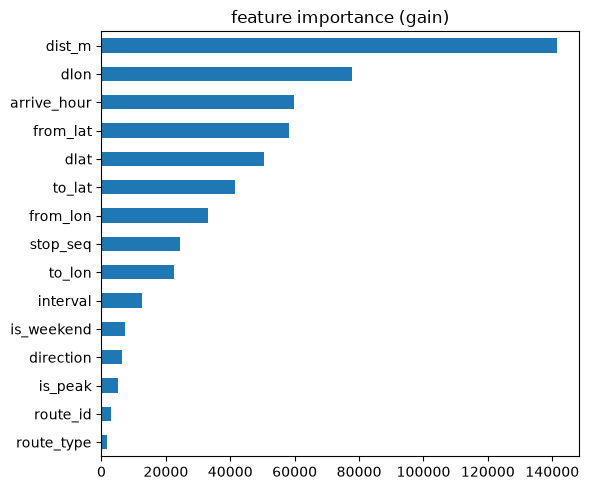

In [11]:
import lightgbm as lgb

params = dict(objective='regression_l1', learning_rate=0.1, num_leaves=127, min_child_samples=50,
              subsample=0.8, subsample_freq=1, colsample_bytree=0.8, n_estimators=1000, random_state=0, verbose=-1)
model = lgb.LGBMRegressor(**params)
model.fit(prep(fit), fit.tt_sec, eval_set=[(prep(val), val.tt_sec)], eval_metric='l1',
          callbacks=[lgb.early_stopping(50, verbose=False)])
pred = model.predict(prep(val))
print(f'LightGBM(검증)  MAE {mae(val.tt_sec, pred):.2f}  RMSE {rmse(val.tt_sec, pred):.2f}   (트리 {model.best_iteration_}개)')

imp = pd.Series(model.booster_.feature_importance('gain'), index=FEATS).sort_values()
imp.plot.barh(figsize=(6, 5)); plt.title('feature importance (gain)'); plt.tight_layout(); plt.show()

## 2-5. 제출 파일 만들고 채점하기
검증에서 정한 트리 개수로 **전체 학습 데이터**를 다시 학습하고, `test`를 예측해 `row_id`, `tt_sec` CSV로 저장함.
연습용 `test`에는 정답이 들어 있어서 바로 채점할 수 있음. (대회 `test`에는 정답이 없으므로 채점은 대회 사이트에서 함.)

> **연습용 `test` 점수는 마지막 확인용임.** 이 점수를 보면서 피처나 파라미터를 고르면 `test`에 맞춰진 모델이 되고,
> 정답이 없는 대회에서는 그렇게 할 수 없음. 모델 선택은 **검증 점수**로 하는 습관을 들일 것.

In [12]:
final = lgb.LGBMRegressor(**{**params, 'n_estimators': model.best_iteration_})
final.fit(prep(train), train.tt_sec)
sub = pd.DataFrame({'row_id': test.row_id, 'tt_sec': final.predict(prep(test)).round(1)})

os.makedirs('../submissions', exist_ok=True)
sub.to_csv(f'../submissions/{PHASE}_lightgbm.csv', index=False)
print(sub.shape, '| 결측', int(sub.tt_sec.isna().sum()), '| row_id 중복', int(sub.row_id.duplicated().sum()))

if 'tt_sec' in test.columns:                      # 연습용 데이터: 정답이 있으므로 채점
    sys.path.append('../src')
    from evaluate import score
    base = pd.DataFrame({'row_id': test.row_id, 'tt_sec': baseline_predict(train, test).values})
    for name, s in [('평균 예측', base), ('LightGBM', sub)]:
        r = score(s, test[['row_id', 'tt_sec']], test)
        print(f"{name:8s} MAE {r['MAE']:.2f}  RMSE {r['RMSE']:.2f}  첨두 {r['첨두 MAE']:.2f}  비첨두 {r['비첨두 MAE']:.2f}")
        print('         노선별', {k: round(v, 2) for k, v in r['노선별 MAE'].items()})

(79942, 2) | 결측 0 | row_id 중복 0
평균 예측    MAE 29.89  RMSE 55.67  첨두 32.58  비첨두 28.44
         노선별 {'1': 35.64, '102': 29.24, '511': 27.58, '605': 29.16}
LightGBM MAE 27.99  RMSE 57.73  첨두 30.04  비첨두 26.88
         노선별 {'1': 33.85, '102': 27.39, '511': 25.3, '605': 27.42}


터미널에서 채점하려면:
```bash
python src/evaluate.py --submission submissions/practice_lightgbm.csv --labels data/practice/test.csv
```

## 다음에 해볼 것
- **새 피처**: 어떤 정류장 구간은 늘 오래 걸리지 않을까? 하루 중 운행이 시작되고 얼마나 지났는지가 영향을 줄까? 같은 버스가 바로 앞 구간에서 느렸다면?
- **다른 모델**: XGBoost, CatBoost, RandomForest 비교
- **오차 분석**: 어떤 노선·시간대에서 많이 틀리는지, 첨두시간 성능
- **하이퍼파라미터 조정**: `num_leaves`, `learning_rate`, `min_child_samples`
- **교차검증**: 날짜별로 돌아가며 검증 (한 날짜만 쓰면 점수가 흔들릴 수 있음)